# Weather Hazard Category (WHC) — 02 EDA & Hazard Creation

**Student Name:** Aryan Goel | **Student ID:** 26040826

---

## 1. WHI & WHC Formulas
1. Hazard Scores:
   - $\text{RainHazard} = \min(\text{precipitation} / 30, 1)$
   - $\text{WindHazard} = \min(\text{wind\_gusts} / 100, 1)$
   - $\text{CloudHazard} = \min(\text{cloud\_cover} / 100, 1)$
   - $\text{SnowHazard} = \min(\text{snowfall} / 15, 1)$
   - $\text{TempHazard} = \min(|\text{temperature} - 22| / 25, 1)$
2. Weather Hazard Index:
   - $\text{WHI} = 100 \times (0.30\text{Rain} + 0.30\text{Wind} + 0.20\text{Cloud} + 0.10\text{Snow} + 0.10\text{Temp})$
3. Categorical Labels:
   - Class 0 (Low Risk): $\text{WHI} < 25$
   - Class 1 (Moderate Risk): $25 \le \text{WHI} < 50$
   - Class 2 (High Risk): $50 \le \text{WHI} < 75$
   - Class 3 (Extreme Risk): $\text{WHI} \ge 75$


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.preprocessing import load_interim_data
from src.targets import calculate_weather_hazard_index, convert_whi_to_whc, WHC_LABEL_TO_NAME

daily_df = load_interim_data()
whi, hazards = calculate_weather_hazard_index(
    precipitation=daily_df["precipitation"],
    wind_gusts_10m=daily_df["wind_gusts_10m"],
    cloud_cover=daily_df["cloud_cover"],
    snowfall=daily_df["snowfall"],
    temperature_2m=daily_df["temperature_2m"],
)
daily_df["whi"] = whi
daily_df["whc"] = convert_whi_to_whc(whi)
daily_df["whc_name"] = daily_df["whc"].map(WHC_LABEL_TO_NAME)

print("WHI Summary:")
print(daily_df["whi"].describe())
print("\nWHC Class Distribution:")
print(daily_df["whc_name"].value_counts())


WHI Summary:
count    2922.000000
mean       27.516801
std        10.943430
min         9.801667
25%        19.847500
50%        25.640833
75%        32.305833
max        83.098333
Name: whi, dtype: float64

WHC Class Distribution:
whc_name
Moderate Risk    1407
Low Risk         1378
High Risk         130
Extreme Risk        7
Name: count, dtype: int64


## 2. Visualizing Class Imbalance & WHI Distributions

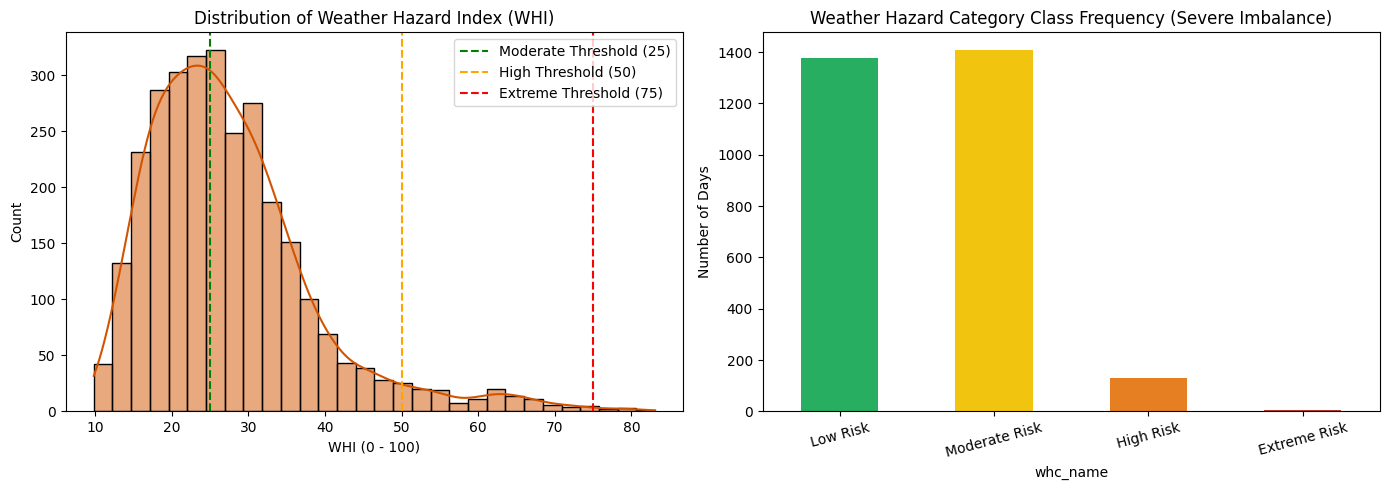

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(daily_df["whi"], kde=True, ax=axes[0], color="#d35400", bins=30)
axes[0].set_title("Distribution of Weather Hazard Index (WHI)")
axes[0].set_xlabel("WHI (0 - 100)")
axes[0].axvline(25, color="green", linestyle="--", label="Moderate Threshold (25)")
axes[0].axvline(50, color="orange", linestyle="--", label="High Threshold (50)")
axes[0].axvline(75, color="red", linestyle="--", label="Extreme Threshold (75)")
axes[0].legend()

class_counts = daily_df["whc_name"].value_counts().reindex(["Low Risk", "Moderate Risk", "High Risk", "Extreme Risk"]).fillna(0)
class_counts.plot(kind="bar", ax=axes[1], color=["#27ae60", "#f1c40f", "#e67e22", "#c0392b"])
axes[1].set_title("Weather Hazard Category Class Frequency (Severe Imbalance)")
axes[1].set_ylabel("Number of Days")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("reports/figures/whc_class_distribution.png", dpi=150)
plt.show()


## 3. Imbalance Insights for Model Architecture
- **Low (47.2%)** and **Moderate (48.2%)** dominate the dataset (>95% combined).
- **High Risk (4.4%)** is infrequent; **Extreme Risk (<0.3%)** is rare (7 days over 8 years).
- A naive majority-class classifier will achieve ~50% raw accuracy while completely failing to detect dangerous hazards.
- **Remedy**: We must employ **cost-sensitive learning** (`class_weight='balanced'`) and evaluate using **Macro F1** and **Balanced Accuracy** rather than raw accuracy.
